(506, 13)
      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   
3  0.03237   0.0   2.18     0  0.458  6.998  45.8  6.0622    3  222     18.7   
4  0.06905   0.0   2.18     0  0.458  7.147  54.2  6.0622    3  222     18.7   

   lstat  medv  
0   4.98  24.0  
1   9.14  21.6  
2   4.03  34.7  
3   2.94  33.4  
4   5.33  36.2  
             crim          zn       indus        chas         nox          rm  \
count  506.000000  506.000000  506.000000  506.000000  506.000000  506.000000   
mean     3.613524   11.363636   11.136779    0.069170    0.554695    6.284634   
std      8.601545   23.322453    6.860353    0.253994    0.115878    0.702617   
min      0.006320    0.000000    0.460000    0.000000    0.385000    3.561000   
25

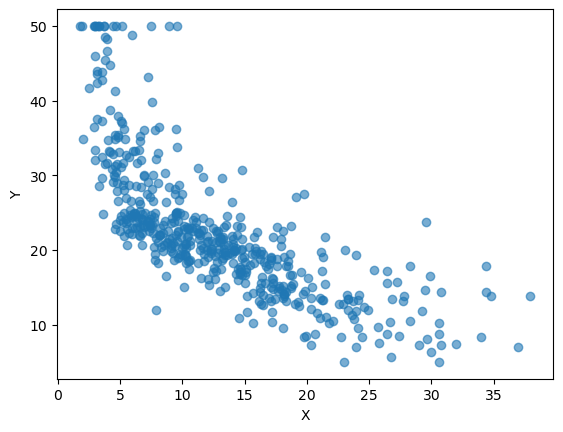

(506, 2)
(506,)
(506, 1)
[[0.]
 [0.]]
(2, 1)
296.0734584980237
[[34.55363411]
 [-0.95003694]]
           coefficient
intercept    34.553634
slope        -0.950037
[[162.79695372]
 [161.99413134]
 [161.64965651]
 [161.30758544]
 [160.96634148]]
[[0.11266403 1.18378616]
 [0.14987214 1.11158577]
 [0.19146198 1.11320064]
 [0.23274171 1.11048068]
 [0.27398713 1.10801862]]
[[34.55363312 -0.95003688]
 [34.55363337 -0.9500369 ]
 [34.55363361 -0.95003691]
 [34.55363386 -0.95003693]
 [34.55363411 -0.95003694]]
         cost  intercept     slope      grad0       grad1
0  162.796954   0.112664  1.183786 -22.532806 -236.757231
1  161.994131   0.149872  1.111586  -7.441621   14.440077
2  161.649657   0.191462  1.113201  -8.317969   -0.322974
3  161.307585   0.232742  1.110481  -8.255946    0.543993
4  160.966341   0.273987  1.108019  -8.249082    0.492412
           cost  intercept     slope    grad0     grad1
9995  19.241484  34.553633 -0.950037 -0.00005  0.000003
9996  19.241484  34.553633 -0.9500

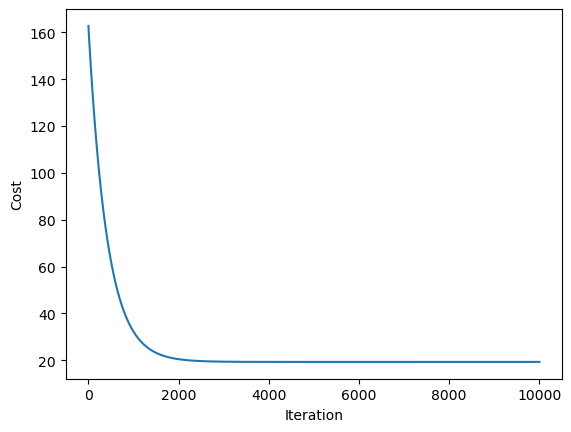

In [5]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-


# ============================================================
# Gradient Descent for Linear Regression
# ============================================================

from ISLP import load_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm




# load data from ISLP package

Boston = load_data("Boston")
Boston.columns

print(Boston.shape)

print(Boston.head())
print(Boston.describe())

# scatter plot

plt.scatter(Boston["lstat"], Boston["medv"], alpha=0.6)

plt.xlabel("X")
plt.ylabel("Y")

plt.show()

# cost function 

def cost(X, y, beta):
    
    y_hat = X @ beta
    error = y - y_hat
    
    cost_value = np.sum(error**2) / (2 * X.shape[0])
    
    return cost_value


# Design matrix:
x = Boston["lstat"].to_numpy(dtype=float)
X = np.column_stack([np.ones(len(Boston)),x])

type(X)
print(X.shape)


# Outcome
y = Boston["medv"].to_numpy(dtype=float)
print(y.shape)

y = y.reshape(-1,1)
print(y.shape)


# initial values

beta = np.array([[0.0], [0.0]])
print(beta)
print(beta.shape)

print(cost(X, y, beta))


# gradient descent 

alpha = 0.005
iterations = 10000


    
n = X.shape[0]

iter_history = np.zeros((iterations, 1))
grad_history = np.zeros((iterations, len(beta)))
est_history = np.zeros((iterations, len(beta)))
   

# iterate for optimization 

for i in range(iterations):
        
   y_hat = X @ beta
   error = y - y_hat
        
   gradient = X.T @ (-1 * error) / n
   beta = beta - alpha * gradient
        
   iter_history[i, 0] = cost(X, y, beta)
   est_history[i, :] = beta.flatten()
   grad_history[i, :] = gradient.flatten()
    

print(beta)

df_beta = pd.DataFrame(beta, index=["intercept", "slope"], columns=["coefficient"])
print(df_beta)


print(iter_history[:5])    # cost
print(est_history[:5, :])  # parameter estimates
print(est_history[-5:, :])


result = np.column_stack((iter_history, est_history, grad_history))
result = pd.DataFrame(result, columns=["cost", "intercept", "slope", "grad0", "grad1"])

print(result.head())
print(result.tail())


# compare with OLS regression 
X_lm = sm.add_constant(Boston["lstat"].astype(float))

lm_fit = sm.OLS(Boston["medv"], X_lm).fit()

print(lm_fit.summary())
print(lm_fit.params)



# plot cost history 

plt.plot(
    np.arange(1, iterations + 1),
    result["cost"]
)

plt.xlabel("Iteration")
plt.ylabel("Cost")

plt.show()


In [3]:
!pip install ISLP

  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
   ---------------------------------------- 0.0/16.6 MB ? eta -:--:--
   - -------------------------------------- 0.6/16.6 MB 19.5 MB/s eta 0:00:01
   --- ------------------------------------ 1.5/16.6 MB 19.1 MB/s eta 0:00:01
   ------ --------------------------------- 2.5/16.6 MB 19.8 MB/s eta 0:00:01
   ------- -------------------------------- 3.3/16.6 MB 18.9 MB/s eta 0:00:01
   ---------- ----------------------------- 4.2/16.6 MB 19.4 MB/s eta 0:00:01
   ------------ --------------------------- 5.2/16.6 MB 19.3 MB/s eta 0:00:01
   -------------- ------------------------- 6.1/16.6 MB 19.6 MB/s eta 0:00:01
   ----------------- ---------------------- 7.2/16.6 MB 19.9 MB/s eta 0:00:01
   ------------------- -------------------- 8.1/16.6 MB 19.9 MB/s eta 0:00:01
   --------------------- ------------------ 9.0/16.6 MB 19.8 MB/s eta 0:00:01
   ------------------------ --------------- 10.0